## Lab 2: Bayesian MCMC

### Question 1: Random-Walk Metropolis-Hastings Algorithm

**Objective:** To implement the Random-Walk Metropolis-Hastings algorithm to generate samples from a standard normal distribution.

Markov Chain Monte Carlo (MCMC) is a statistical method used to generate samples from complex probability distributions.

The Metropolis-Hastings algorithm works by proposing new values and accepting or rejecting them based on an acceptance probability.

The target distribution in this experiment is the standard normal distribution:

X ~ N(0, 1)

The acceptance probability is:

α(x, x') = min(1, π(x') / π(x))

Where π(x) represents the target probability density.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Define the standard normal target distribution

def target_distribution(x):
    return np.exp(-0.5 * x**2)

In [3]:
# Random-Walk Metropolis-Hastings algorithm

def metropolis_hastings(n_samples, proposal_std=1.0):

    # Initialize the chain
    samples = np.zeros(n_samples)

    # Starting value
    current = 0.0

    # Acceptance counter
    accepted = 0

    for i in range(n_samples):

        # Propose a new value
        proposal = np.random.normal(current, proposal_std)

        # Calculate acceptance probability
        acceptance_ratio = (
            target_distribution(proposal) /
            target_distribution(current)
        )

        acceptance_probability = min(1, acceptance_ratio)

        # Accept or reject the proposal
        if np.random.rand() < acceptance_probability:
            current = proposal
            accepted += 1

        # Store the current value
        samples[i] = current

    acceptance_rate = accepted / n_samples

    return samples, acceptance_rate

In [4]:
# Set random seed for reproducibility
np.random.seed(42)

# Generate samples
samples, acceptance_rate = metropolis_hastings(
    n_samples=10000,
    proposal_std=1.0
)

# Display results
print("First 10 samples: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:11")
print(samples[:10])

print("\nSample mean: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:14", np.mean(samples))
print("Sample standard deviation: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:15", np.std(samples))

print("Acceptance rate: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:17", acceptance_rate)

First 10 samples: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:11
[ 0.49671415  0.35844985  0.12429648 -0.10984048  1.46937234  1.46937234
  0.99989795  1.54245799  1.78442026 -0.12885998]

Sample mean: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:14 0.05488577403564897
Sample standard deviation: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:15 1.0000961984158574
Acceptance rate: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:17 0.7116


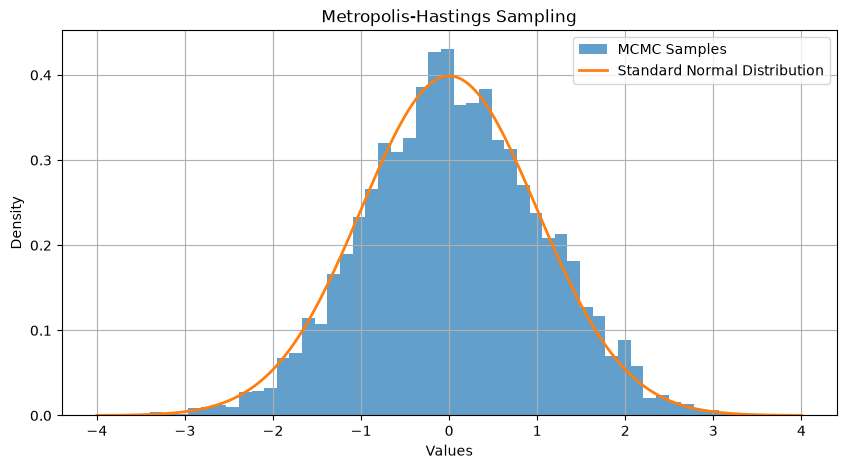

In [5]:
# Plot histogram of generated samples

plt.figure(figsize=(10, 5))

plt.hist(samples, bins=50, density=True, alpha=0.7,
         label="MCMC Samples")

# Plot theoretical standard normal density
x = np.linspace(-4, 4, 200)

y = (1 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * x**2)

plt.plot(x, y, linewidth=2, label="Standard Normal Distribution")

plt.title("Metropolis-Hastings Sampling")
plt.xlabel("Values")
plt.ylabel("Density")
plt.legend()
plt.grid(True)

plt.show()

### Conclusion

The Random-Walk Metropolis-Hastings algorithm was successfully implemented to generate samples from a standard normal distribution.

The algorithm proposed new values using a normal proposal distribution and accepted or rejected them based on the Metropolis-Hastings acceptance probability.

The generated samples approximately followed a standard normal distribution with a mean close to 0 and a standard deviation close to 1.

This demonstrates how MCMC methods can be used to approximate probability distributions through repeated sampling.

### Question 2: Bayesian Estimation of a Bernoulli Probability

**Objective:** To estimate the probability of success using Bayesian inference with a Beta(2,2) prior after observing 8 successes in 12 trials.

Given:

- Prior distribution: Beta(2,2)
- Number of successes: 8
- Total trials: 12
- Number of failures: 4

The Beta distribution is a probability distribution used to represent uncertainty about an unknown probability.

The posterior distribution is calculated using:

Beta(alpha + successes, beta + failures)

Therefore:

Posterior = Beta(2 + 8, 2 + 4)

Posterior = Beta(10,6)

The posterior mean is:

E(p) = alpha / (alpha + beta)

E(p) = 10 / (10 + 6) = 0.625

Therefore, the estimated probability of success is 62.5%.

In [6]:
import numpy as np
from scipy.stats import beta

# Define the prior parameters
alpha_prior = 2
beta_prior = 2

# Observed data
successes = 8
trials = 12
failures = trials - successes

# Calculate posterior parameters
alpha_posterior = alpha_prior + successes
beta_posterior = beta_prior + failures

# Calculate posterior mean
posterior_mean = alpha_posterior / (
    alpha_posterior + beta_posterior
)

# Display results
print("Prior Distribution: Beta(2,2)")

print("Number of successes:", successes)
print("Number of failures:", failures)

print("Posterior Distribution: Beta(",
      alpha_posterior, ",", beta_posterior, ")")

print("Posterior Mean:", posterior_mean)

print("Estimated Probability of Success:",
      posterior_mean * 100, "%")

Prior Distribution: Beta(2,2)
Number of successes: 8
Number of failures: 4
Posterior Distribution: Beta( 10 , 6 )
Posterior Mean: 0.625
Estimated Probability of Success: 62.5 %


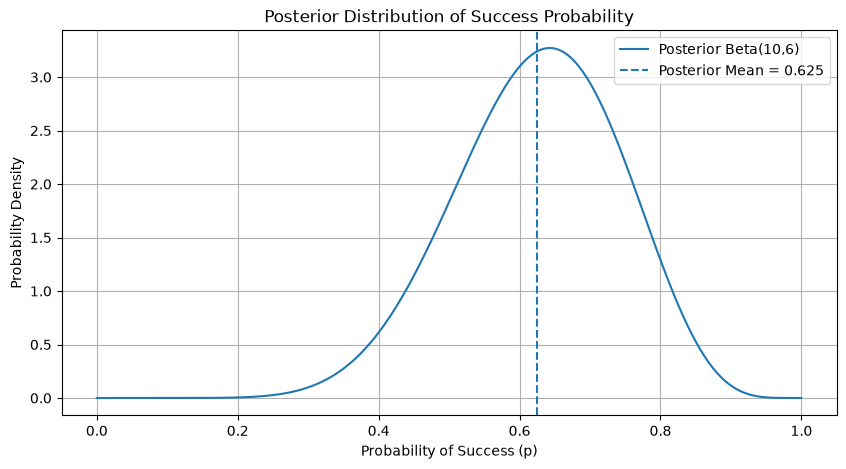

In [7]:
# Generate values between 0 and 1
x = np.linspace(0, 1, 500)

# Calculate posterior probability density
y = beta.pdf(x, alpha_posterior, beta_posterior)

# Plot posterior distribution
plt.figure(figsize=(10, 5))

plt.plot(x, y, label="Posterior Beta(10,6)")

plt.axvline(
    posterior_mean,
    linestyle="--",
    label="Posterior Mean = 0.625"
)

plt.title("Posterior Distribution of Success Probability")
plt.xlabel("Probability of Success (p)")
plt.ylabel("Probability Density")

plt.legend()
plt.grid(True)

plt.show()

### Conclusion

Bayesian estimation was successfully performed using a Beta(2,2) prior and Bernoulli observations consisting of 8 successes in 12 trials.

The resulting posterior distribution was Beta(10,6).

The posterior mean was calculated as 0.625, indicating an estimated probability of success of 62.5%.

This demonstrates how Bayesian inference combines prior knowledge with observed data to update our beliefs about an unknown probability.

### Question 3: Explain Trace Plots, ACF, R-hat, and ESS

MCMC diagnostics are statistical tools used to evaluate the convergence, mixing, and efficiency of Markov Chain Monte Carlo algorithms.

**1. Trace Plots**

A trace plot is a graphical representation of sampled parameter values against the iteration number.

It is used to monitor the behaviour of an MCMC chain and determine whether it has reached a stable distribution. A well-behaved trace plot should show random fluctuations around a stable region without obvious trends.

**2. Autocorrelation Function (ACF)**

ACF measures the correlation between observations at different time lags in a sequence.

In MCMC, consecutive samples may be correlated because each new sample depends on the previous state. ACF helps determine the level of dependence between samples and assess how efficiently the chain mixes.

**3. R-hat (Gelman-Rubin Statistic)**

R-hat is a convergence diagnostic that compares within-chain and between-chain variation across multiple MCMC chains.

It helps determine whether different chains have converged to the same target distribution. An R-hat value close to 1 indicates good convergence. Modern practice generally recommends values below 1.01.

**4. Effective Sample Size (ESS)**

ESS estimates the number of independent samples represented by a correlated MCMC sample.

It measures sampling efficiency by accounting for autocorrelation. A higher ESS generally indicates more efficient sampling and more reliable statistical estimates.

**Conclusion:**

Trace plots, ACF, R-hat, and ESS are important MCMC diagnostic tools. Together, they help assess chain stability, autocorrelation, convergence, and sampling efficiency.


### Question 4: PyMC Model for Normally Distributed Observations

**Objective:** To construct a Bayesian statistical model using PyMC for normally distributed observations.

PyMC is a Python library used for probabilistic programming and Bayesian statistical modelling.

In this experiment, we assume that the observed data follow a normal distribution:

X ~ Normal(μ, σ)

Where:
- μ represents the unknown population mean.
- σ represents the unknown population standard deviation.

We assign prior distributions to the unknown parameters and use MCMC sampling to estimate their posterior distributions.

In [9]:
%pip install pymc

  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached markdown_it_py-4.2.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ---------------------------------------- 0.0/608.3 kB ? eta -:--:--
   ----------------- ---------------------- 262.1/608.3 kB ? eta -:--:--
   ---------------------------------------- 608.3/608.3 kB 3.7 MB/s  0:00:00
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------------------------------------ --- 1.3/1.4 MB 6.7 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 6.2 MB/s  0:00:00
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----------------------- ---------------- 1.0/1.8 MB 6.3 MB/s eta 0:00:01
   ----------------------------- ---------- 1.3/1.8 MB 3.0 MB/s eta 0:00:01
   ------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.14.1 requires fsspec>=0.8.5, which is not installed.
torch 2.14.1 requires networkx>=2.5.1, which is not installed.


In [10]:
import pymc as pm

print("PyMC version:", pm.__version__)

g++ not available, if using conda: `conda install gxx`


PyMC version: 6.3.2


In [11]:
import numpy as np

# Observed data
data = np.array([12, 14, 13, 15, 16, 14, 13, 15, 17, 14])

# Display the data
print("Observed data: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:7", data)

print("Sample mean: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:9", np.mean(data))
print("Sample standard deviation: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:10", np.std(data, ddof=1))

Observed data: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:7 [12 14 13 15 16 14 13 15 17 14]
Sample mean: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:9 14.3
Sample standard deviation: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:10 1.4944341180973264


In [12]:
import pymc as pm

# Define the Bayesian model
with pm.Model() as normal_model:

    # Prior distribution for the mean
    mu = pm.Normal("mu", mu=0, sigma=10)

    # Prior distribution for the standard deviation
    sigma = pm.HalfNormal("sigma", sigma=10)

    # Likelihood function
    likelihood = pm.Normal(
        "likelihood",
        mu=mu,
        sigma=sigma,
        observed=data
    )

print("PyMC normal model created successfully. - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:20")

PyMC normal model created successfully. - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:20


In [13]:
# Perform MCMC sampling
with normal_model:

    trace = pm.sample(
        draws=2000,
        tune=1000,
        chains=4,
        random_seed=42,
        return_inferencedata=True
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, sigma]


c:\Users\asus\.conda\envs\icd341\Lib\site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter 
support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 13 seconds.


In [14]:
# Display posterior summary
summary = pm.summary(trace, var_names=["mu", "sigma"])

print(summary)

        mean    sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
mu     14.26  0.57       13       15     4631     3999  1.00    0.0089   0.011
sigma   1.76  0.52      1.2      2.7     4292     4191  1.00    0.0085   0.013


C:\Users\asus\AppData\Local\Temp\ipykernel_5908\1304747051.py:2: DeprecationWarning: `pymc.summary` was moved out of the root namespace and will be removed in the first PyMC release of 2027. Use `pymc.stats.summary` instead.
  summary = pm.summary(trace, var_names=["mu", "sigma"])


## Visualizing the Posterior Distributions

Posterior distributions are visualized using histograms to examine the estimated population mean and standard deviation.

The plots help us understand the uncertainty surrounding the estimated parameters.

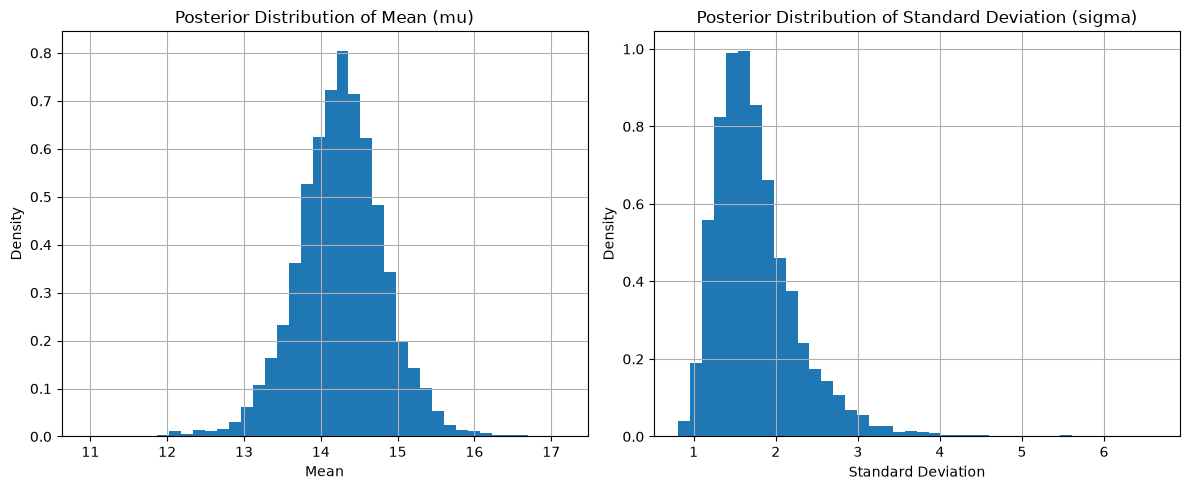

In [17]:
import matplotlib.pyplot as plt

# Extract posterior samples
mu_samples = trace.posterior["mu"].values.flatten()
sigma_samples = trace.posterior["sigma"].values.flatten()

# Create figure
plt.figure(figsize=(12, 5))

# Plot posterior distribution of mu
plt.subplot(1, 2, 1)
plt.hist(mu_samples, bins=40, density=True)
plt.title("Posterior Distribution of Mean (mu)")
plt.xlabel("Mean")
plt.ylabel("Density")
plt.grid(True)

# Plot posterior distribution of sigma
plt.subplot(1, 2, 2)
plt.hist(sigma_samples, bins=40, density=True)
plt.title("Posterior Distribution of Standard Deviation (sigma)")
plt.xlabel("Standard Deviation")
plt.ylabel("Density")
plt.grid(True)

plt.tight_layout()
plt.show()

In [18]:
print("PyMC version: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:1", pm.__version__)
print("Posterior mean: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:2", mu_samples.mean())
print("Posterior standard deviation: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:3", sigma_samples.mean())

print("\nModel sampling completed successfully. - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:5")

PyMC version: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:1 6.3.2
Posterior mean: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:2 14.258251152983634
Posterior standard deviation: - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:3 1.757371660205589

Model sampling completed successfully. - ICD341_Lab10_Mwila_Singoma_202401774.ipynb:5


### Conclusion

A Bayesian normal model was successfully constructed using PyMC.

Normal and Half-Normal prior distributions were assigned to the unknown population mean and standard deviation, respectively.

The observed data were modelled using a normal likelihood function.

MCMC sampling was performed using four independent chains to estimate the posterior distributions of the parameters.

The posterior summary provided estimates of the population mean and standard deviation, together with convergence diagnostics such as R-hat and effective sample size.

This demonstrates how PyMC can be used to perform Bayesian statistical modelling and parameter estimation.